# Practical 10: Principal Component Analysis

**Dataset:** Wine (178 samples, 13 chemical measurements, 3 wine classes)

**Aim:** Explore the wine data, scale the features and use principal components to show class separation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = pd.read_csv("wine.csv")
print(wine.shape)
wine.head()

(178, 14)


   class  alcohol  malic_acid  ...   hue  od280/od315_of_diluted_wines  proline
0      1    14.23        1.71  ...  1.04                          3.92   1065.0
1      1    13.20        1.78  ...  1.05                          3.40   1050.0
2      1    13.16        2.36  ...  1.03                          3.17   1185.0
3      1    14.37        1.95  ...  0.86                          3.45   1480.0
4      1    13.24        2.59  ...  1.04                          2.93    735.0

[5 rows x 14 columns]

In [2]:
wine.info()
print(wine["class"].value_counts().sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   class                         178 non-null    int64  
 1   alcohol                       178 non-null    float64
 2   malic_acid                    178 non-null    float64
 3   ash                           178 non-null    float64
 4   alcalinity_of_ash             178 non-null    float64
 5   magnesium                     178 non-null    float64
 6   total_phenols                 178 non-null    float64
 7   flavanoids                    178 non-null    float64
 8   nonflavanoid_phenols          178 non-null    float64
 9   proanthocyanins               178 non-null    float64
 10  color_intensity               178 non-null    float64
 11  hue                           178 non-null    float64
 12  od280/od315_of_diluted_wines  178 non-null    float64
 13  proline         

**Result:** The data has 178 samples and 14 columns (the class label and 13 features) with no missing values. There are three wine classes.

In [3]:
wine.describe().round(3)

         class  alcohol  ...  od280/od315_of_diluted_wines   proline
count  178.000  178.000  ...                       178.000   178.000
mean     1.938   13.001  ...                         2.612   746.893
std      0.775    0.812  ...                         0.710   314.907
min      1.000   11.030  ...                         1.270   278.000
25%      1.000   12.362  ...                         1.938   500.500
50%      2.000   13.050  ...                         2.780   673.500
75%      3.000   13.678  ...                         3.170   985.000
max      3.000   14.830  ...                         4.000  1680.000

[8 rows x 14 columns]

**Result:** The features are on very different scales. For example proline has values in the hundreds while hue is close to 1. This is why scaling is needed before PCA.

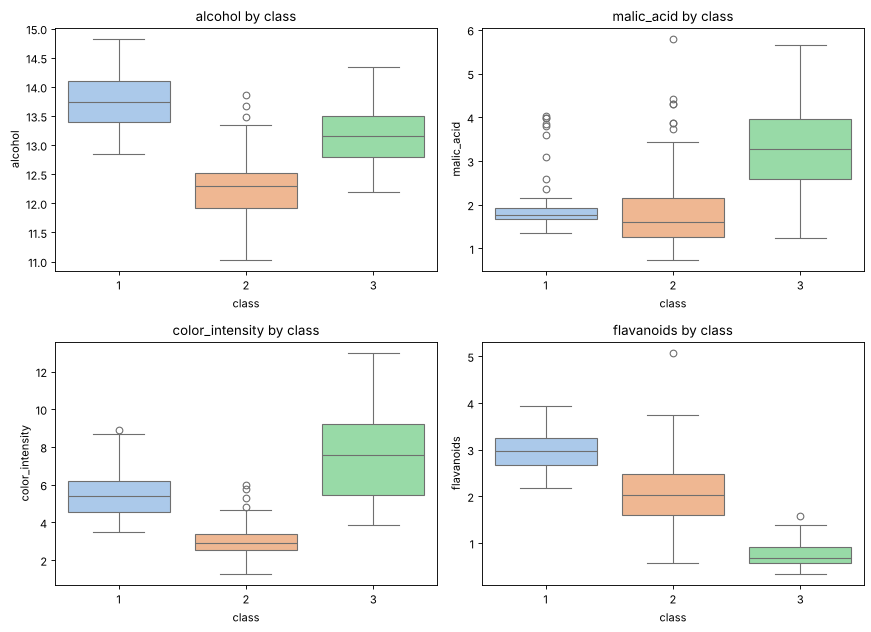

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), ["alcohol", "malic_acid", "color_intensity", "flavanoids"]):
    sns.boxplot(data=wine, x="class", y=col, hue="class", palette="pastel", legend=False, ax=ax)
    ax.set_title(col + " by class")
plt.tight_layout()
plt.show()

**Result:** The classes differ clearly. Class 1 has high alcohol and high flavanoids, class 2 has low colour intensity and class 3 has high colour intensity and low flavanoids. The dots outside the whiskers are outliers.

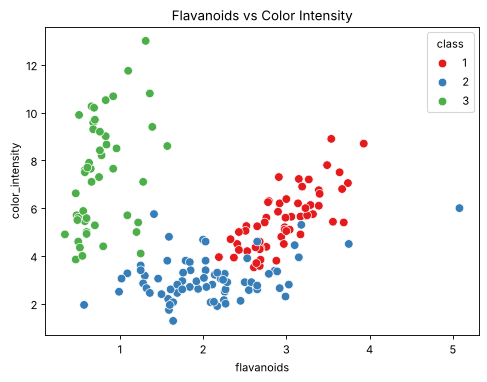

In [5]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=wine, x="flavanoids", y="color_intensity", hue="class", palette="Set1", s=60)
plt.title("Flavanoids vs Color Intensity")
plt.show()

**Result:** Two features already separate most of the classes, but the groups still overlap in places, so two original features alone are not enough.

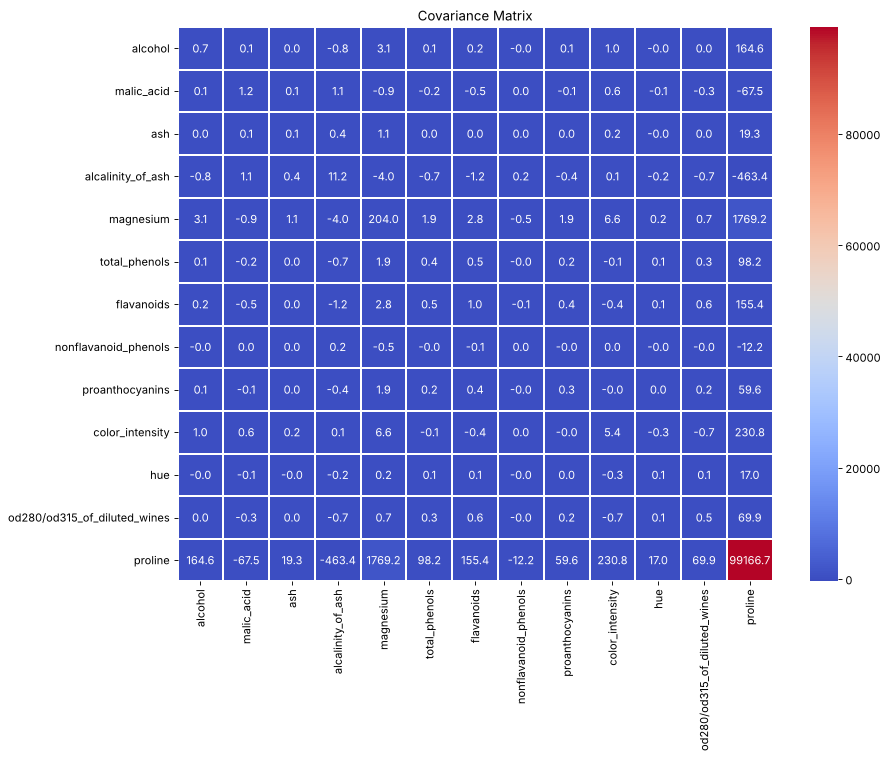

In [6]:
features = wine.drop(columns="class")
covariance = features.cov()
plt.figure(figsize=(12, 9))
sns.heatmap(covariance, annot=True, fmt=".1f", cmap="coolwarm", linewidths=0.4)
plt.title("Covariance Matrix")
plt.show()

**Result:** Proline has a very large variance compared with all other features, so it would dominate the analysis without scaling.

In [7]:
scaler = StandardScaler()
scaled = pd.DataFrame(scaler.fit_transform(features), columns=features.columns)
print(scaled.head())
print("Mean after scaling:")
print(scaled.mean().round(2))
print("Std after scaling:")
print(scaled.std().round(2))

    alcohol  malic_acid  ...  od280/od315_of_diluted_wines   proline
0  1.518613   -0.562250  ...                      1.847920  1.013009
1  0.246290   -0.499413  ...                      1.113449  0.965242
2  0.196879    0.021231  ...                      0.788587  1.395148
3  1.691550   -0.346811  ...                      1.184071  2.334574
4  0.295700    0.227694  ...                      0.449601 -0.037874

[5 rows x 13 columns]
Mean after scaling:
alcohol                        -0.0
malic_acid                     -0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                   0.0
flavanoids                     -0.0
nonflavanoid_phenols            0.0
proanthocyanins                -0.0
color_intensity                 0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0
dtype: float64
Std after scaling:
alcohol                         1.0
malic

**Result:** After standardization every feature has mean 0 and standard deviation 1, so all features contribute equally.

In [8]:
pca = PCA(n_components=2)
components = pca.fit_transform(scaled)
pc = pd.DataFrame(components, columns=["PC1", "PC2"])
pc["class"] = wine["class"].to_numpy()
ratio = pca.explained_variance_ratio_
print(pc.head())
print("Explained variance ratio:", np.round(ratio, 4))
print("Total variance explained:", round(ratio.sum() * 100, 2), "%")

        PC1       PC2  class
0  3.316751  1.443463      1
1  2.209465 -0.333393      1
2  2.516740  1.031151      1
3  3.757066  2.756372      1
4  1.008908  0.869831      1
Explained variance ratio: [0.362  0.1921]
Total variance explained: 55.41 %


**Result:** PC1 explains 36.20% and PC2 explains 19.21% of the variance. Together the two components keep 55.41% of the information in the 13 features.

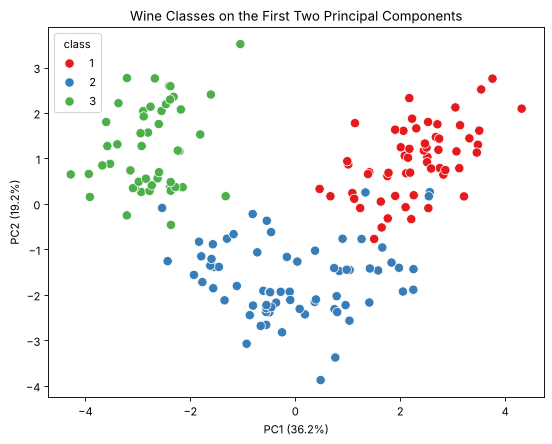

In [9]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pc, x="PC1", y="PC2", hue="class", palette="Set1", s=70)
plt.title("Wine Classes on the First Two Principal Components")
plt.xlabel("PC1 (" + str(round(ratio[0] * 100, 1)) + "%)")
plt.ylabel("PC2 (" + str(round(ratio[1] * 100, 1)) + "%)")
plt.show()

**Result:** The three wine classes form three clearly separated groups on PC1 and PC2, with much less overlap than in the scatter plot of the original features. PCA therefore gives better class separation using just two components.